<a href="https://colab.research.google.com/github/juanerickgabi-ship/PROYECTO-ACELERADOR-LINEAL/blob/main/Problema_Plano_inclinado_angulo_variante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROBLEMA DE PLANO INCLINADO CON ANGULO VARIANTE
**Integrantes:**
*   Gabriela Herrera Ortiz
*   Juan Esteban Muñoz Bravo
*   Erick Mateo Garcia Diaz

**Enunciado:**
Calcular mediante codigo Python la aceleracion, la velocidad y el tiempo
que demora el bloque de masa m en llegar al final del plano de longitud d (la aceleracion de la gravedad es g) con angulo variante del plano inclinado con respecto a la horizontal, analizar el caso con y sin friccion, verificar los resultados por conservación de energía. En el caso con $\mu \neq 0$ tambien analizar el coeficiente de friccion cambiante a partir de la funcion gaussiana.

---

**Graficos del problema**


*   Caso sin fricción:


    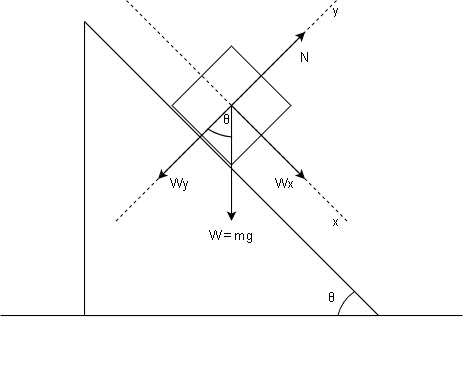


* Caso con fricción:


    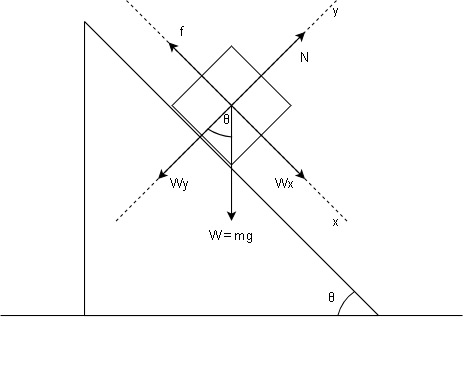

---

# DESARROLLO DEL PROBLEMA

## LIBRERIAS

Librerias necesarias para correr el codigo y menus del codigo.

In [ ]:
#===============================================================================

#LIBRERIAS
import math as m
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import lineStyles
from inspect import FrameInfo
#===============================================================================

### MENUS

In [ ]:
#Menu principal para preguntarle a el usuario si desea tratar el caso sin o con friccion
main_menu =["Caso sin friccion","Caso con friccion","Salir"]

#Menu secundario para preguntar al usuario si desea ver algo mas: Como graficas de Conservacion de energia
second_menu = ["Si","No"]


#FUNCION PARA IMPRIMIR UN MENU DEFINIDO CON ANTERIORIDAD
def imprimir_menu(estructura):
    """
    FUNCION PARA IMPRIMIR UN MENU Y TAMBIEN SOLICITAR UNA OPCION AL USUARIO

    Parametros:
    -esctructura: Es una entrada que representa una lista, tupla o diccionario

    Salidas:
    -En caso de ser una tupla o lista: (en este caso una lista)
    imprime un menu en el rango (primer termino[0] hasta el ultimo valor de la lista o tupla)
    con su respectivo numero para despues pedirle al usuario que ingrese una opcion.

    -En caso de ser un diccionario:
    imprime un menu (se usa la funcion estructuta.items() para recorrer el diccionario)
    extrayendo el valor de cada llave y su respectivo valor.

    -Opcion que eligio el usuario de acuerdo al menu
    """
    if isinstance(estructura, (list, tuple)):
    #Imprimir menu con un "for-each" y "range" en caso de ser una lista o tupla
        for i in range(0, len(estructura)):
            print(f"{i + 1}. {estructura[i]}")
    #Imprimir un menu usando la funcion ".items" en caso de ser un diccionario(dejarlo en caso de necesitar)
    else:
        for k, v in estructura.items():
            print(f"{k}. {v}")

    #solicitar al usuario elegir una opción del menu que se imprimio atraves de un "while True" y un try-except para evitar que el usuario ingrese un valor distinto al maximo de valores en la lista, tupla o diccionario

    while True:
        try:
            opt = int(input("Ingrese su opción: "))
            if opt >= 1 and opt <= len(estructura):
                return opt
            else:
                print("\nLa opción es incorrecta")
        except ValueError:
            print("La opción es incorrecta")

## DINAMICA DE UN CUERPO EN PLANO INCLINADO

La dinámica del sistema se fundamenta en la segunda ley de
Newton, según la cual la fuerza resultante que actúa sobre
un cuerpo es igual al producto de su masa por su aceleración. Es decir:

$\sum \overrightarrow{F}= m \overrightarrow{a}$

El peso del cuerpo es $\overrightarrow{W} = m \overrightarrow{a}$, en este caso si se toma el sistema de referencia en el bloque que esta sobre el plano inclinado, por diagrama de cuerpo libre se encuentra que:

* La componente del peso sobre el eje x es: $W_x = mgsinθ$
* La componente del peso sobre el eje y es: $W_y = mgcosθ$



## CASO SIN FRICCION ($\mu = 0$)


### ECUACIONES DE MOVIMIENTO SIN FRICCION

Considerando que entre el plano inclinado y el bloque no hay fuerza de fricción entonces por segunda ley de Newton se tiene que las fuerzas que actuan sobre él en el sistema de referencia elegido son:

$\sum F_y = N - W_y = N - mgcos\theta = 0$

$\sum F_x = W_x = mgsin\theta = ma$

De la anterior ecuacion queda la siguiente igualdad:

$mgsin\theta = ma$

Despejando la aceleración:

$a = gsin\theta$

Como el bloque parte del reposo, su velocidad con la que llega al final del plano inclinado es:

$v = \sqrt{2gdsin\theta}$

Donde la distancia del plano inclinado $d=\frac{1}{2}at^2$ por lo que el tiempo con el bloque llega al final del plano inclinado es:

$t = \sqrt{\frac{2d}{gsinθ}}$

Estas ecuaciones estan definidas en la funcion ```equa_mov_sinfric(rad)```





In [ ]:
def equa_mov_sinfric(rad):
    """

    FUNCION CON LAS ECUACIONES DE MOVIMIENTO SIN FRICCION DEL BLOQUE EN EN EL PLANO INCLINADO

    Parametros:
    rad: angulo en radianes

    Salidas:
    a: aceleracion del bloque
    v: velocidad con la que llega el bloque al final del plano inclinado partiendo del reposo
    t: tiempo de llegada del bloque al final del plano inclinado

    """
    a = g * m.sin(rad)
    v = m.sqrt(2*a*d)
    t = m.sqrt(2*d/a)
    return a,v,t



### CONSERVACION DE ENERGIA SIN FRICCION

Por la geometria del sistema se sabe la altura h es: $h = d * sinθ$, por tanto la energía potencial U es:

$U = mhg$

Al partir del reposo y con fricción nula, el bloque tiene energia cinetica K igual a su energia potencial por que: $K=U$. Por lo que

$\frac{1}{2}mv^2 = U$

Despejando la velocidad:

$v = \sqrt{\frac{2U}{m}}$

Aplicando la misma ecuacion para la velocidad en las ecuaciones de movimiento, la aceleración es:

$a = \frac{v^2}{2*d}$

y el tiempo:

$t = \sqrt{\frac{2d}{a}}$

Estas ecuaciones estan presentes en la función ```conservacion_energia_nofr(rad)```



In [ ]:
def conservacion_energia_nofr(rad):

    """
    FUNCION DE VERIFICACION POR CONSERVACION DE ENERGIA DEL BLOQUE EN EL PLANO INCLINADO SIN FRICCION

    Parametros:
    rad: angulo en radianes

    Salidas:
    h: altura en la que llega el bloque al final del plano inclinado
    U: energia potencial
    K: energia cinetica

    """
    h = d*m.sin(rad)        #Altura en metros
    U = masa*h*g            #Energia potencial en Julios
    K = U                   #Energia cinetica en Julios
    v = m.sqrt((2*U)/masa)  #velocidad
    a = v**2/(2*d)          #aceleracion
    t = m.sqrt(2*d/a)       #tiempo

    return h,U,K,v,a,t


## CASO CON FRICCION ($\mu \neq 0$)

### ECUACIONES DE MOVIMIENTO CON FRICCION


Considerando que entre el plano inclinado y el bloque si hay fuerza de fricción que se opone al movimiento del bloque entonces por segunda ley de Newton se tiene que las fuerzas que actuan sobre él en el sistema de referencia elegido son:

$\sum F_y = N - W_y = N - mgcos\theta = 0 \Rightarrow N = mgcosθ$

$\sum F_x = f - W_x = \mu N - mgsin\theta = ma \Rightarrow \mu mgcosθ  - mgsin\theta = ma$

De la anterior ecuacion queda la siguiente igualdad:

$\mu mgcosθ  - mgsin\theta = ma$

Despejando la aceleración:

$a=g(\sin{θ}-μ\cos{θ})$

si la aceleracion es negativa entonces no hay movimiento por lo tanto $v,t = 0$, sin embargo cuando la aceleracion es positiva y como el bloque parte del reposo, su velocidad con la que llega al final del plano inclinado es: $v = \sqrt{2ad}$


Tiempo de llegada hasta el fin del plano:
$t=\sqrt{\frac{2*d}{a}}$

Estas ecuaciones estan definidas en la función ```equa_mov_confric(rad,mu)```

In [ ]:

#FUNCION ECUACIONES DE MOVIMIENTO CON FRICCION
def equa_mov_confric(rad,mu):
    """
    FUNCION ECUACIONES DE MOVIMIENTO CON FRICCION

    Parametros:
    rad: angulo en radianes
    mu: coeficiente de friccion

    Salidas:
    a_fr: aceleracion
    v_fr: velocidad
    t_fr: tiempo
    """

    a_fr = g*(m.sin(rad) - mu*m.cos(rad))
    if a_fr < 0:
        v_fr = 0
        t_fr = 0 #?
    else:
        v_fr = m.sqrt(2*a_fr*d)
        t_fr = m.sqrt(2*d/a_fr)

    return a_fr,v_fr,t_fr

### CONSERVACION DE LA ENERGIA CON FRICCION


El trabajo realizado por la fuerza de friccion es $W_{f} = f*d $ y como la energia potencial es $U = mgh$ entonces la energía cinetica es:

K = U - $W_{f}$

Ahora si K es negativo ($W_f > U$) entonces la aceleracion es $a=\frac{K}{md}$ y por lo tanto no hay movimiento. Si K es positivo entonces se aplican las mismas ecuaciones de movimiento para el caso sin fricción.

Estas ecuaciones estan definidas en la función ```
conservacion_energia_confric(rad,mu)```



In [ ]:
#FUNCION DE VERIFICACION POR CONSERVACION DE ENERGIA CON FRICCION
def conservacion_energia_confric(rad,mu):

    """

    FUNCION DE VERIFICACION POR CONSERVACION DE ENERGIA DEL BLOQUE EN EL PLANO INCLINADO CON FRICCION

    Parametros:
    rad: angulo en radianes
    mu: coeficiente de friccion

    Salidas:
    h: altura maxima del plano inclinado que cambia debido al angulo
    U: energia potencial
    K: energia cinetica
    E: energia total
    v: velocidad
    a: aceleracion
    t: tiempo

    """
    h = d * m.sin(rad)
    U = masa * h *g
    K = U - (mu * masa * g * m.cos(rad) * d)
    E = U + K
    if K < 0:
        v = 0
        a = (K/masa)/d
        t = 0
    else:
        v = m.sqrt((2*K)/masa)
        a = v**2/(2*d)
        t = m.sqrt(2*d/a)
    return h,U,K,E,v,a,t


### μ VARIANTE CON LA FUNCION GAUSSIANA

Considerando la funcion gaussiana:

$f(x) = \frac{1}{\sigma \sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2 \sigma ^2}}$

donde el maximo valor es $\frac{1}{\sigma \sqrt{2\pi}}$, el punto central de la campana gaussiana es el coeficiente de fricción $\mu$ y $\sigma$ es la desviación estandar.

Por propagacion de errores se tiene que:

*   Para la **aceleracion en funcion del coeficiente de fricción**:

    a($\mu$) = $gsin\theta - \mu gcosθ$

    Derivando la aceleracion con respecto a $\mu$ se tiene que:

    $\frac{da}{d\mu} = -gcosθ$

    Considerando el valor absoluto de la derivada y multiplicando por la desviacion estandar $\sigma$ se obtiene el error en la aceleración:

    $\sigma_a = \left| \frac{da}{d\mu} \right| \sigma = \sigma gcosθ$.

*   Para **la velocidad en funcion del coeficiente de fricción**:
    
    $v(μ) = \sqrt{2d*a(\mu)}$

    Haciendo el mismo procedimiento anterior se tiene que:

    $\sigma_v = \left| \frac{dv}{d\mu} \right| \sigma =\frac{gdcosθ}{v(\mu)} σ$

*   Para **el tiempo en funcion del coeficiente de fricción**:
    
    $t(\mu) = \sqrt{\frac{2d}{a(μ)}}$

    Por lo tanto:

    $\sigma_t = \left| \frac{dt}{d\mu} \right| \sigma =\frac{gdcosθ}{a(μ)*v(\mu)} σ$

Estas operaciones estan hechas por la funcion ```mu_gaussiana(ang, rad, mu) ``` la cual abre un archivo.txt con los datos de aceleracion, velocidad, tiempo, sus respectivos errores y angulos en grados y radianes.

Luego la funcion ```mostrar_mu_gaussiana(archivo)``` muestra los datos del archivo.txt anterior en pantalla y por último la funcion ``` mu_gaussiana_graf(mu) ``` grafica la funcion gaussiana con centro en el coeficiente de fricción.

In [ ]:
def mu_gaussiana(ang, rad, mu):
    with open('DATOS: MU VARIANTE CON ANGULO VARIANTE', 'w') as arch_mu:
        arch_mu.write("Grados Radianes Aceleracion Error_a Velocidad Error_v Tiempo Error_t\n")
        for grados, radianes in zip(ang, theta):
            a1, v1, t1 = equa_mov_confric(radianes,mu)
            cos_theta = m.cos(radianes)
            desv = mu/10

            sigma_a = g*cos_theta*desv
            if a1 < 0:
                sigma_v = 0
                sigma_t = 0
            else:
                sigma_v = ((g*d*cos_theta)/v1) * desv
                sigma_t = (g*d*cos_theta)/(a1*v1) *desv

            arch_mu.write(f"{grados:.2f} {radianes:.2f} {a1:.2f} {sigma_a:.4f} {v1:.2f} {sigma_v:.4f} {t1:.2f} {sigma_t:.4f}\n")



def mostrar_mu_gaussiana(archivo):
    datos = np.loadtxt(archivo, skiprows=1)
    grados = datos[:, 0]
    radianes = datos[:, 1]
    aceleracion = datos[:, 2]
    sigma_a = datos[:, 3]
    velocidad = datos[:, 4]
    sigma_v = datos[:, 5]
    tiempo = datos[:, 6]
    sigma_t = datos[:, 7]

    for i in range(len(datos)):
        print(f"{grados[i]:6.1f}°  ",
              f"{radianes[i]:8.3f} rad",
              f"a_fr = {aceleracion[i]:8.3f} m/s^2",
              f"sigma_a = {sigma_a[i]:8.3f}",
              f"v_fr = {velocidad[i]:8.3f} m/s",
              f"sigma_v = {sigma_v[i]:8.3f}",
              f"t_fr = {tiempo[i]:8.3f} s",
              f"sigma_t = {sigma_t[i]:8.3f}")


def mu_gaussiana_graf(mu):
    mu_min = mu - 0.15
    mu_max = mu + 0.15
    dst = mu/6 #Para una mejor visualizacion
    x = np.linspace(mu_min, mu_max, 500)

    a_pic = 1/(dst*np.sqrt(2*np.pi))

    y = a_pic * np.exp((-(x - mu)**2) / (2*dst**2))

    plt.figure(figsize=(8, 5))
    plt.plot(x, y, color='blue', linewidth=2, label=fr"Distribución de $\mu$(Centro = {mu}, Desviación estandar = {dst:.2f})")
    plt.fill_between(x, y, color='blue', alpha=0.1)
    plt.axvline(x=mu, color='red', linestyle='--', label=fr"$\mu$ = {mu}")
    plt.xlabel(r'Coeficientes de friccion $\mu$')
    plt.ylabel('Densidad de probabilidad')
    plt.title(r'Distribución Gaussiana de coeficiente de friccion $\mu$')

    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.legend(frameon=True,loc='upper right', fontsize=10)
    plt.tight_layout()

    plt.show()

    plt.savefig('Distribucion_gaussiana_mu.pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.savefig('Distribucion_gaussiana_mu.png', format='png', dpi=300, bbox_inches='tight')

## Funciones para crear archivos.txt




In [ ]:
#FUNCION PARA ABRIR UN ARCHIVO CON DATOS CON EC.MOV SIN FRICCION
def Archivo_texto_nofr(ang,theta):
    """

    FUNCION PARA ABRIR ARCHIVO DE TEXTO .txt
    Los archivos contiene los datos de las correspondientes variables que cambian con el angulo de inclinacion


    Parametros:
    ang: angulo en grados
    theta: angulo en radianes

    Salidas:
    -Archivo de texto .txt llamado "DATOS: ANGULO VARIANTE SIN FRICCION"


    """

    with open('DATOS: ANGULO VARIANTE SIN FRICCION', 'w') as archive1:
        archive1.write("Grados  Radianes    Aceleracion Velocidad   Tiempo\n")
        for grados, radianes in zip(ang, theta):
            a1, v1, t1 = equa_mov_sinfric(radianes)
            archive1.write(f"{grados:.2f}    {radianes:.2f}    {a1:.2f}    {v1:.2f}    {t1:.2f}\n")

#_______________________________________________________________________________
#FUNCION PARA ABRIR ARCHIVO CONSERVACION DE ENERGIA SIN FRICCION

def Archivotxt_cons_en_sinfr(ang,theta):

    with open('DATOS: CONSERVACION DE LA ENERGIA SIN FRICCION', 'w') as archive2:
        archive2.write("Altura    Energia Potencial    Energia cinetica    Velocidad    Aceleracion    Tiempo\n")
        for grados, radianes in zip(ang, theta):
            h2, U2, K2, v2, a2, t2 = conservacion_energia_nofr(radianes)
            archive2.write(f"{grados:.2f}    {h2:.2f}    {U2:.2f}    {K2:.2f}    {v2:.2f}    {a2:.2f}    {t2:.2f}\n")


#_______________________________________________________________________________
#FUNCION ABRIR UN ARCHIVO CON LOS DATOS CONSIDERANDO LA FRICCION

def Archivo_texto_confr(ang,theta,mu):

    """
    FUNCION ABRIR UN ARCHIVO CON LOS DATOS CONSIDERANDO LA FRICCION

    Parametros:
    ang: angulo en grados
    theta: angulo en radianes
    mu: coeficiente de friccion

    Salidas:
    -Archivo de texto .txt llamado "DATOS: ANGULO VARIANTE CON FRICCION"
    """


    with open('DATOS: ANGULO VARIANTE CON FRICCION', 'w') as archive1:
        archive1.write("Grados  Radianes    Aceleracion Velocidad   Tiempo\n")
        for grados, radianes in zip(ang, theta):
            a1, v1, t1 = equa_mov_confric(radianes,mu)
            archive1.write(f"{grados:.2f}    {radianes:.2f}    {a1:.2f}    {v1:.2f}    {t1:.2f}\n")

#_______________________________________________________________________________
#FUNCION ABRIR ARCHIVO CONSERVACION DE ENERGIA CON FRICCION
def Archivotxt_cons_en_confr(ang,theta,mu):

    """
    FUNCION ABRIR ARCHIVO CONSERVACION DE ENERGIA DEL BLOQUE EN EL PLANO INCLINADO CON FRICCION

    Parametros:
    ang: angulo en grados
    theta: angulo en radianes
    mu: coeficiente de friccion

    Salidas:
    -Archivo de texto .txt llamado "DATOS: CONSERVACION DE LA ENERGIA CON FRICCION"

    """

    with open('DATOS: CONSERVACION DE LA ENERGIA CON FRICCION', 'w') as archive2:
        archive2.write("Altura    Energia Potencial    Energia cinetica Energia Mecanica  Velocidad    Aceleracion    Tiempo\n")
        for grados, radianes in zip(ang, theta):
            h2, U2, K2, E, v2, a2, t2 = conservacion_energia_confric(radianes,mu)
            archive2.write(f"{grados:.2f}   {h2:.2f}    {U2:.2f}    {K2:.2f}   {E:.2f}    {v2:.2f}    {a2:.2f}    {t2:.2f}\n")



## FUNCIONES PARA GRAFICAR

Las siguientes funciones tambien sirven para visualizar en consola los datos del **archivo.txt** correspondiente.

### GRAFICAS SIN FRICCION

In [ ]:
#_______________________________________________________________________________
#FUNCION GRAFICAR DATOS POR ECUACIONES DE MOVIMIENTO SIN FRICCION
def graficas_equa_mov_sinfr(archivo):

    """

    FUNCION GRAFICAR POR ECUACIONES DE MOVIMIENTO LA ACELERACION, LA VELOCIDAD Y EL TIEMPO EN FUNCION DEL ANGULO

    Parametros:
    archivo: es una entrada que representa el archivo.txt con los datos de la aceleracion, velocidad y tiempo con angulo variante

    Salidas:
    -Grafica Aceleracion vs Angulo
    -Grafica Velocidad vs Angulo
    -Grafica Tiempo vs Angulo
    -Grafica con las tres variables con angulo variante
    -Grafica con subplots con las 4 graficas anteriores

    """

    datos = np.loadtxt(archivo, skiprows=1)

    #Sacar columnas del archivos
    grados = datos[:, 0]
    radianes = datos[:, 1]
    aceleracion = datos[:, 2]
    velocidad = datos[:, 3]
    tiempo = datos[:, 4]

    print("-"*10)
    print("DATOS DEL ARCHIVO:", archivo)
    print("Número de datos:", len(grados))
    print("-"*10)

    #Imprimir cada dato en pantalla
    for i in range(len(grados)):
        print(f"{grados[i]:6.1f}°  "
          f"{radianes[i]:8.3f} rad  "
          f"a = {aceleracion[i]:8.3f} m/s²  "
          f"v = {velocidad[i]:8.3f} m/s  "
          f"t = {tiempo[i]:8.3f} s")
    print("-"*100)

    #---------------------------------------------------------------------------
    #---------------------------GRAFICAS----------------------------------------
    #---------------------------------------------------------------------------

    print("\n----GRAFICAS ECUACIONES DE MOVIMIENTO SIN FRICCION----\n")

    #1.GRAFICA ACELERACION VS ANGULO

    plt.figure(figsize=(8, 5))

    plt.plot(grados, aceleracion, marker='o', markersize=6, linewidth=2
             , linestyle='-',color='red', label='Aceleración')
    plt.xlabel('Ángulo (grados)',fontsize=12)
    plt.ylabel('Aceleración (m/s^2)', fontsize=12)
    plt.title('Aceleración en función del angulo')
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.tight_layout()
    #Guardar grafica
    plt.savefig('Aceleracion-angulo.pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('Aceleracion-angulo.png', format='png',
                dpi=300, bbox_inches='tight')


    #2.GRAFICA VELOCIDAD VS ANGULO

    plt.figure(figsize=(8, 5))

    plt.plot(grados, velocidad, marker='o', markersize=6, linewidth=2
             , linestyle='-',color='blue', label='Velocidad')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Velocidad (m/s)', fontsize=12)
    plt.title('Velocidad en función del angulo')
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.tight_layout()
    #Guardar grafica
    plt.savefig('Velocidad-angulo.pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('Velocidad-angulo.png', format='png',
                dpi=300, bbox_inches='tight')

    #GRAFICA TIEMPO VS ANGULO

    plt.figure(figsize=(8, 5))

    plt.plot(grados, tiempo, marker='o', markersize=6, linewidth=2
             , linestyle='-',color='green', label='Tiempo')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Tiempo (s)', fontsize=12)
    plt.title('Tiempo en función del ángulo')
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.tight_layout()
    #Guardar grafica
    plt.savefig('Tiempo-angulo.pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('Tiempo-angulo.png', format='png',
                dpi=300, bbox_inches='tight')


    #4.GRAFICA TRIPLE
    plt.figure(figsize=(8, 5))

    plt.plot(grados, aceleracion, marker='o', markersize=6, linewidth=2
             , linestyle='-',color='red', label='Aceleración(m/s^2)')
    plt.plot(grados, velocidad, marker='o', markersize=6, linewidth=2
             , linestyle='-',color='blue', label='Velocidad(m/s)')
    plt.plot(grados, tiempo, marker='o', markersize=6, linewidth=2
             , linestyle='-',color='green', label='Tiempo(s)')

    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Valor de la variable', fontsize=12)
    plt.title('Aceleración, Velocidad y Tiempo en función del ángulo')
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.tight_layout()
    #Guardar grafica
    plt.savefig('Aceleracion-Velocidad-Tiempo_vs_angulo.pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('Aceleracion-Velocidad-Tiempo_vs_angulo.png', format='png',
                dpi=300, bbox_inches='tight')

    #---------------------------------------------------------------------------
    #-----------------MATRIZ PARA HACER SUBPLOTS--------------------------------
    #---------------------------------------------------------------------------

    #MATRIZ 2X2 PARA LAS ANTERIORES GRAFICAS
    fig, ax = plt.subplots(2, 2, figsize=(10, 10))


    #1. Aceleracion: Pocision fila 1 columna 1(superior izquierda)
    ax[0, 0].plot(grados, aceleracion, marker='o', linewidth=2, color='red')

    ax[0, 0].set_xlabel('Angulo (grados)')
    ax[0, 0].set_ylabel('Aceleración (m/s^2)')
    ax[0, 0].set_title('Aceleración en función del ángulo')
    ax[0, 0].grid(True, linestyle='--', lw=0.7, alpha=0.5)


    #2. Velocidad: Posicion fila 1 columna 2(superior derecha)

    ax[0, 1].plot(grados, velocidad, marker='o', linewidth=2, color='blue')

    ax[0, 1].set_xlabel('Angulo (grados)')
    ax[0, 1].set_ylabel('Velocidad (m/s)')
    ax[0, 1].set_title('Velocidad en función del ángulo')
    ax[0, 1].grid(True, linestyle='--', lw=0.7, alpha=0.5)

    #3. Tiempo: Posicion fila 2 columna 1(inferior izquierda)

    ax[1, 0].plot(grados, tiempo, marker='o', linewidth=2, color='green')

    ax[1, 0].set_xlabel('Angulo (grados)')
    ax[1, 0].set_ylabel('Tiempo (s)')
    ax[1, 0].set_title('Tiempo en función del ángulo')
    ax[1, 0].grid(True, linestyle='--', lw=0.7, alpha=0.5)

    #4.Combinado: Posicion fila 2 columna 2(inferior derecha)

    ax[1, 1].plot(grados, aceleracion, marker='o', linewidth=2, color='red', label='Aceleracion')
    ax[1, 1].plot(grados, velocidad, marker='o', linewidth=2, color='blue', label='Velocidad')
    ax[1, 1].plot(grados, tiempo, marker='o', linewidth=2, color='green', label='Tiempo')

    ax[1, 1].set_xlabel('Angulo (grados)')
    ax[1, 1].set_ylabel('Valor de la variable')
    ax[1, 1].set_title('Aceleración, Velocidad y Tiempo en función del ángulo')
    ax[1, 1].grid(True, linestyle='--', lw=0.7, alpha=0.5)
    ax[1, 1].legend(frameon=True, loc='best', fontsize=10)

    plt.tight_layout() # Ajustar automáticamente los espacios

    plt.savefig('_SUBPLOTS_Aceleracion-Velocidad-Tiempo_vs_angulo.pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('_SUBPLOTS_Aceleracion-Velocidad-Tiempo_vs_angulo.png', format='png',
                dpi=300, bbox_inches='tight')

    plt.show()


#_______________________________________________________________________________
#FUNCION GRAFICAR ENERGIA VS ANGULO VARIANTE SIN FRICCION
def graficas_energia_sinfric(archivo):

    """
    FUNCION GRAFICAR ENERGIA VS ANGULO VARIANTE

    Parametros:
    archivo: entrada que representa el nombre del archivo.txt

    Salidas:
    -Grafica altura vs angulo variante
    -Grafica energia potencial y cinetica vs angulo variante
    -Grafica con subplots con las dos graficas anteriores
    -Grafica aceleracion, velocidad y tiempo en funcion del angulo
    """


    datos = np.loadtxt(archivo, skiprows=1)

    grados = datos[:, 0]
    altura = datos[:, 1]
    potencial = datos[:, 2]
    cinetica = datos[:, 3]
    velocidad = datos[:, 4]
    aceleracion = datos[:, 5]
    tiempo = datos[:, 6]

    print("-"*10)
    print("NOMBRE DEL ARCHIVO:", archivo)
    print("Número de datos:", len(datos))
    print("-"*10)

    for i in range(len(grados)):
        print(f"{grados[i]:6.1f}°  ",
              f"h = {altura[i]:8.3f} m  ",
              f"U = {potencial[i]:8.3f} J  ",
              f"K = {cinetica[i]:8.3f} J  ",
              f"v = {velocidad[i]:8.3f} m/s",
              f"a = {aceleracion[i]:8.3f} m/s^2",
              f"t = {tiempo[i]:8.3f} s")

    print("\n----GRAFICAS ENERGIA VS ANGULO VARIANTE SIN FRICCION----\n")

    col_1 = '#D2691E' #Chocolate
    col_2 = '#556B2F' #verde ocuro vivo
    col_3 = '#FF69B4' #rosa oscuro

    #1. Altura vs angulo variante

    plt.figure(figsize=(8, 5))

    plt.plot(grados, altura, marker='o', markersize=6, linewidth=2
             , linestyle='-',color = col_1, label='Altura')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Altura (m)', fontsize=12)
    plt.title('Altura en funcion del angulo de inclinacion')
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.tight_layout()

    plt.savefig('Altura-angulo_SIN FRICCION.pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('Altura-angulo_SIN FRICCION.png', format='png',
                dpi=300, bbox_inches='tight')


    #2.Energia Potencial y cinetica en funcion del angulo

    plt.figure(figsize=(8, 5))

    plt.plot(grados, potencial, marker='o', markersize=6, linewidth=2
             , linestyle='-',color = col_2, label='Energia Potencial')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Energia Potencial (J)', fontsize=12)
    plt.title('Energia Potencial (y Cinetica)  en funcion del angulo de inclinacion')
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.tight_layout()

    plt.savefig('Energia_potencial-angulo_SIN FRICCION.pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('Energia_potencial-angulo_SIN FRICCION.png', format='png',
                dpi=300, bbox_inches='tight')


    #3. POR MATRIZ 1X2 (Se tiene que moificar en caso de hacer mas graficas arriba)


    fig, ax = plt.subplots(1, 2, figsize=(14, 10))

    ax[0].plot(grados, altura, marker='o', linewidth=2, color=col_1)
    ax[0].set_xlabel('Angulo (grados)')
    ax[0].set_ylabel('Altura (m)')
    ax[0].set_title('Altura en funcion del angulo de inclinacion')
    ax[0].grid(True, linestyle='--', lw=0.7, alpha=0.5)

    ax[1].plot(grados, potencial, marker='o', linewidth=2, color=col_2, label='Energia Potencial')
    ax[1].set_xlabel('Angulo (grados)')
    ax[1].set_ylabel('Energia Potencial (J)')
    ax[1].set_title('Energia Potencial en funcion del angulo de inclinacion')
    ax[1].grid(True, linestyle='--', lw=0.7, alpha=0.5)

    plt.tight_layout()

    plt.savefig('_SUBPLOTS_SIN FRICCION_Altura-EnergiaPotencial-angulo_SIN FRICCION.pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('_SUBPLOTS_SIN FRICCION_Altura-EnergiaPinetica-angulo_SIN FRICCION.png', format='png',
                dpi=300, bbox_inches='tight')


    #4 Grafica aceleracion, velocida, tiempo en funcion del angulo

    plt.figure(figsize=(8, 5))
    plt.plot(grados, aceleracion, marker='o', linewidth=2, color='red', label='Aceleracion(m/s^2)')
    plt.plot(grados, velocidad, marker='o', linewidth=2, color='blue', label='Velocidad(m/s)')
    plt.plot(grados, tiempo, marker='o', linewidth=2, color='green', label='Tiempo(s)')
    plt.xlabel('Angulo (grados)')
    plt.ylabel('Valor de la variable')
    plt.title('Aceleracion, Velocidad y Tiempo en funcion del angulo(Por Energía)')
    plt.grid(True, linestyle='--', lw=0.7, alpha=0.5)
    plt.legend(frameon=True, loc='best', fontsize=10)
    plt.tight_layout()

    plt.savefig('_SUBPLOTS_SIN FRICCION_Aceleracion-Velocidad-Tiempo_vs_angulo(por energia).pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('_SUBPLOTS_SIN FRICCION_Aceleracion-Velocidad-Tiempo_vs_angulo(por energia).png', format='png',
                dpi=300, bbox_inches='tight')

    plt.show()




### GRAFICAS CON FRICCION

In [ ]:

#_______________________________________________________________________________
#________________________________CON FRICCION___________________________________
#_______________________________________________________________________________


#_______________________________________________________________________________
#FUNCION PARA GRAFICAR CASO CON FRICCION
def graficas_equa_mov_confric(archivo,mu):

    """
    FUNCION GRAFICAR ECUACIONES DE MOVIMIENTO CONSIDERANDO LA FRICCION

    Parametros:
    archivo: entrada que representa el nombre del archivo.txt
    mu: coeficiente de friccion

    Salidas:
    -Graficas de aceleracion, velocidad y tiempo en funcion del angulo
    """

    datos = np.loadtxt(archivo, skiprows=1)


    grados = datos[:, 0]
    radianes = datos[:, 1]
    aceleracion = datos[:, 2]
    velocidad = datos[:, 3]
    tiempo = datos[:, 4]

    print("-"*10)
    print("NOMBRE DEL ARCHIVO:", archivo)
    print("Número de datos:", len(datos))
    print("-"*10)

    #Imprimir en pantalla
    for i in range(len(datos)):
        print(f"{grados[i]:6.1f}°  ",
              f"{radianes[i]:8.3f} rad",
              f"a_fr = {aceleracion[i]:8.3f}",
              f"v_fr = {velocidad[i]:8.3f}",
              f"t_fr = {tiempo[i]:8.3f}")

    #----------------------------GRAFICAS---------------------------------------
    print("\n----GRAFICAS ECUACIONES DE MOVIMIENTO CIN FRICCION----\n")
    #1.Aceleracion vs angulo
    plt.figure(figsize=(8, 5))

    plt.plot(grados, aceleracion, marker='o', markersize=6, linewidth=2
             , linestyle='-',color='red', label='Aceleración(m/s^2)')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Aceleración (m/s^2)', fontsize=12)
    plt.title('Aceleración en función del ángulo con friccion')
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.tight_layout()

    plt.savefig('Aceleracion-angulo_con_friccion.pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.savefig('Aceleracion-angulo_con_friccion.png', format='png', dpi=300, bbox_inches='tight')

    #2.Velocidad vs angulo
    plt.figure(figsize=(8, 5))

    plt.plot(grados, velocidad, marker='o', markersize=6, linewidth=2
             , linestyle='-',color='blue', label='Velocidad(m/s)')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Velocidad (m/s)', fontsize=12)
    plt.title('Velocidad en función del ángulo con friccion')
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.tight_layout()

    plt.savefig('Velocidad-angulo_con_friccion.pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.savefig('Velocidad-angulo_con_friccion.png', format='png', dpi=300, bbox_inches='tight')

    #3.Tiempo vs angulo
    plt.figure(figsize=(8, 5))

    plt.plot(grados, tiempo, marker='o', markersize=6, linewidth=2
             , linestyle='-',color='green', label='Tiempo(s)')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Tiempo (s)', fontsize=12)
    plt.title('Tiempo en función del ángulo con friccion')
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.tight_layout()

    plt.savefig('Tiempo-angulo_con_friccion.pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.savefig('Tiempo-angulo_con_friccion.png', format='png', dpi=300, bbox_inches='tight')

    #4. Las 3 variables en una sola grafica
    plt.figure(figsize=(8, 5))

    plt.plot(grados, aceleracion, marker='o', linewidth=2, color='red', label='Aceleracion(m/s^2)')
    plt.plot(grados, velocidad, marker='o', linewidth=2, color='blue', label='Velocidad(m/s)')
    plt.plot(grados, tiempo, marker='o', linewidth=2, color='green', label='Tiempo(s)')

    plt.xlabel('Angulo (grados)')
    plt.ylabel('Valor de la variable')
    plt.title('Aceleracion, Velocidad y Tiempo en funcion del angulo con friccion')
    plt.grid(True, linestyle='--', lw=0.7, alpha=0.5)
    plt.legend(frameon=True, loc='best', fontsize=10)
    plt.tight_layout()

    plt.savefig('_FRICCION_Aceleracion-Velocidad-Tiempo_vs_angulo.pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.savefig('_FRICCION_Aceleracion-Velocidad-Tiempo_vs_angulo.png', format='png', dpi=300, bbox_inches='tight')

    #5.Por matriz 2x2
    fig, ax = plt.subplots(2, 2, figsize=(14, 10))

    ax[0, 0].plot(grados, aceleracion, marker='o', linewidth=2, color='red')
    ax[0, 0].set_xlabel('Angulo (grados)')
    ax[0, 0].set_ylabel('Aceleración (m/s^2)')
    ax[0, 0].set_title('Aceleración en función del ángulo con friccion')
    ax[0, 0].grid(True, linestyle='--', lw=0.7, alpha=0.5)

    ax[0, 1].plot(grados, velocidad, marker='o', linewidth=2, color='blue')
    ax[0, 1].set_xlabel('Angulo (grados)')
    ax[0, 1].set_ylabel('Velocidad (m/s)')
    ax[0, 1].set_title('Velocidad en función del ángulo con friccion')
    ax[0, 1].grid(True, linestyle='--', lw=0.7, alpha=0.5)

    ax[1, 0].plot(grados, tiempo, marker='o', linewidth=2, color='green')
    ax[1, 0].set_xlabel('Angulo (grados)')
    ax[1, 0].set_ylabel('Tiempo (s)')
    ax[1, 0].set_title('Tiempo en función del ángulo con friccion')
    ax[1, 0].grid(True, linestyle='--', lw=0.7, alpha=0.5)

    ax[1,1].plot(grados, aceleracion, marker='o', linewidth=2, color='red', label='Aceleracion')
    ax[1,1].plot(grados, velocidad, marker='o', linewidth=2, color='blue', label='Velocidad')
    ax[1,1].plot(grados, tiempo, marker='o', linewidth=2, color='green', label='Tiempo')
    ax[1,1].set_xlabel('Angulo (grados)')
    ax[1,1].set_ylabel('Valor de la variable')
    ax[1,1].set_title('Aceleracion, Velocidad y Tiempo en funcion del angulo con friccion')
    ax[1,1].legend(frameon=True, loc='best', fontsize=10)
    ax[1,1].grid(True, linestyle='--', lw=0.7, alpha=0.5)

    plt.tight_layout()

    plt.savefig('_SUBPLOTS_FRICCION_Aceleracion-Velocidad-Tiempo_vs_angulo.pdf', format='pdf',
                dpi=300, bbox_inches='tight')
    plt.savefig('_SUBPLOTS_FRICCION_Aceleracion-Velocidad-Tiempo_vs_angulo.png', format='png',
                dpi=300, bbox_inches='tight')


    plt.show()

#_______________________________________________________________________________
#FUNCION PARA GRAFICAR ENERGIA VS ANGULO CON FRICCION
def graficas_energia_confric(archivo,mu):

    datos = np.loadtxt(archivo, skiprows=1)
    grados = datos[:, 0]
    altura = datos[:, 1]
    potencial = datos[:, 2]
    cinetica = datos[:, 3]
    mecanica = datos[:, 4]
    velocidad = datos[:, 5]
    aceleracion = datos[:, 6]
    tiempo = datos[:, 7]

    for i in range(len(grados)):
        print(f"{grados[i]:6.1f}°  ",
              f"h = {altura[i]:8.3f} m  ",
              f"U = {potencial[i]:8.3f} J  ",
              f"K = {cinetica[i]:8.3f} J  ",
              f"E = {mecanica[i]:8.3f} J  ",
              f"v = {velocidad[i]:8.3f} m/s",
              f"a = {aceleracion[i]:8.3f}",
              f"t = {tiempo[i]:8.3f} s")

    col_1 = '#D2691E' #Chocolate
    col_2 = '#556B2F' #verde ocuro vivo
    col_3 = '#FF69B4' #rosa oscuro

    print("\n----GRAFICAS CONSERVACION DE ENERGIA CON FRICCION----\n")

    plt.figure(figsize=(8, 5))

    plt.plot(grados, altura, marker='o', markersize=6, linewidth=2
             , linestyle='-',color = col_1, label='Altura')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Altura (m)', fontsize=12)
    plt.title('Altura en funcion del angulo de inclinacion')
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.tight_layout()
    plt.savefig('Altura-angulo_CON FRICCION (por energia).pdf', format='pdf',dpi=300, bbox_inches='tight')
    plt.savefig('Altura-angulo_CON FRICCION (por energia).png', format='png', dpi=300, bbox_inches='tight')


    plt.figure(figsize=(8, 5))

    plt.plot(grados, potencial, marker='o', markersize=6, linewidth=2
             , linestyle='-',color = col_2, label='Energia Potencial')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Energia Potencial (J)', fontsize=12)
    plt.title('Energia Potencial en funcion del angulo de inclinacion')
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.tight_layout()

    plt.savefig('Energia_potencial-angulo_CON FRICCION (por energia).pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.savefig('Energia_potencial-angulo_CON FRICCION (por energia).png', format='png', dpi=300, bbox_inches='tight')

    plt.figure(figsize=(8, 5))

    plt.plot(grados, cinetica, marker='o', markersize=6, linewidth=2
             , linestyle='-',color = col_3, label='Energia cinetica')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Energia cinetica (J)', fontsize=12)
    plt.title('Energia cinetica en funcion del angulo de inclinacion')
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.tight_layout()

    plt.savefig('Energia_cinetica-angulo_CON FRICCION (por energia).pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.savefig('Energia_cinetica-angulo_CON FRICCION (por energia).png', format='png', dpi=300, bbox_inches='tight')

    plt.figure(figsize=(8, 5))

    plt.plot(grados, mecanica, marker='o', markersize=6, linewidth=2
             , linestyle='-',color = '#2F4F4F', label='Energia Mecanica')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Energia Mecanica (J)', fontsize=12)
    plt.title('Energia Mecanica en funcion del angulo de inclinacion')
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.tight_layout()

    plt.savefig('Energia_mecanica-angulo_CON FRICCION (por energia).pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.savefig('Energia_mecanica-angulo_CON FRICCION (por energia).png', format='png', dpi=300, bbox_inches='tight')

    plt.figure(figsize=(8, 5))

    plt.plot(grados, aceleracion, marker='o', markersize = 6, linewidth=2
             , linestyle='-',color = 'red', label='Aceleracion(m/s^2)')
    plt.plot(grados, velocidad, marker='o', markersize = 6, linewidth=2
             , linestyle='-',color = 'blue', label='Velocidad(m/s)')
    plt.plot(grados, tiempo, marker='o', markersize = 6, linewidth=2
             , linestyle='-',color = 'green', label='Tiempo(s)')
    plt.xlabel('Angulo (grados)',fontsize=12)
    plt.ylabel('Valor de la variable', fontsize=12)
    plt.title('Aceleracion, Velocidad y Tiempo en funcion del angulo de inclinacion (por energia)')
    plt.legend(frameon=True,loc='best', fontsize=10)
    plt.grid(True, linestyle='--',lw=0.7,alpha=0.5)
    plt.tight_layout()

    plt.savefig('Aceleracion-Velocidad-Tiempo-angulo_CON FRICCION (por energia).pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.savefig('Aceleracion-Velocidad-Tiempo-angulo_CON FRICCION (por energia).png', format='png', dpi=300, bbox_inches='tight')



    plt.show()

#_______________________________________________________________________________


## CODIGO PRINCIPAL

Este es el codigo central del programa el cual pide los datos al usuario como son el angulo y la cantidad de pasos para dividir ese angulo y hacerlo variar. Ademas le da la opción al usuario de elegir que caso tratar y si desea ver la verificacion con conservacion de la energía, esto se logra atrevez de 2 menus previamente creados y se los imprime con la funcion ```imprimir_menu(estructura)```y con un ```match-case``` el usuario elige la opcion que desee las cuales estan definidas por la funciones de las anteriores celdas del Notebook.



--------------------------- PROGRAMA PLANO INCLINADO CON ANGULO VARIANTE ---------------------------

Ingrese el angulo maximo en grados (°): 
60
Ingrese cada cuanto quiere que varie el angulo del plano inclinado: 10
__________________________________________________

MENU PRINCIPAL

1. Caso sin friccion
2. Caso con friccion
3. Salir
Ingrese su opción: 1

CASO SIN FRICCION

----------
DATOS DEL ARCHIVO: DATOS: ANGULO VARIANTE SIN FRICCION
Número de datos: 10
----------
   1.0°     0.020 rad  a =    0.170 m/s²  v =    1.660 m/s  t =    9.670 s
   7.6°     0.130 rad  a =    1.290 m/s²  v =    4.540 m/s  t =    3.520 s
  14.1°     0.250 rad  a =    2.390 m/s²  v =    6.190 m/s  t =    2.590 s
  20.7°     0.360 rad  a =    3.460 m/s²  v =    7.440 m/s  t =    2.150 s
  27.2°     0.480 rad  a =    4.490 m/s²  v =    8.470 m/s  t =    1.890 s
  33.8°     0.590 rad  a =    5.450 m/s²  v =    9.340 m/s  t =    1.710 s
  40.3°     0.700 rad  a =    6.350 m/s²  v =   10.080 m/s  t =    1.590 s
 

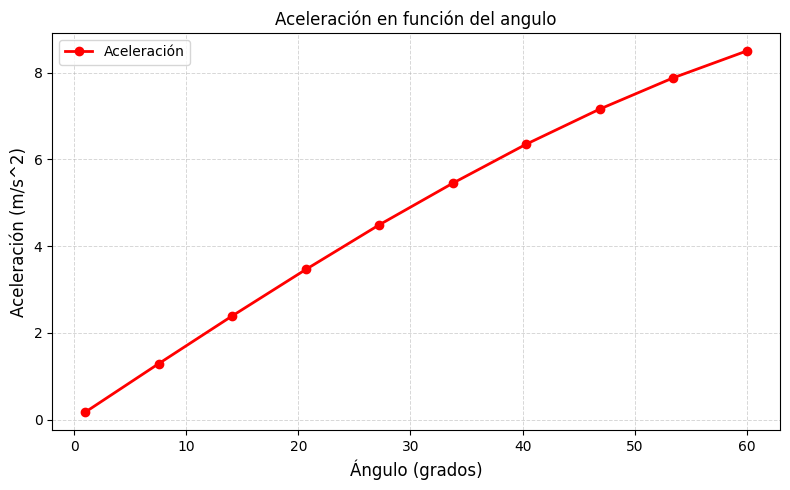

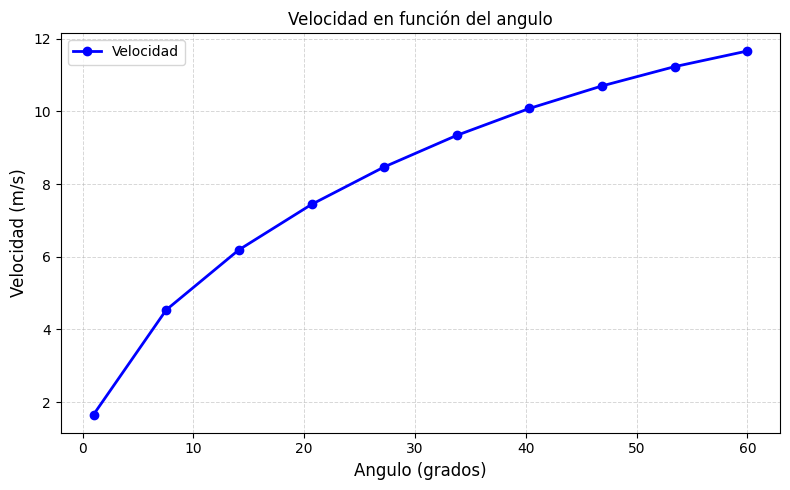

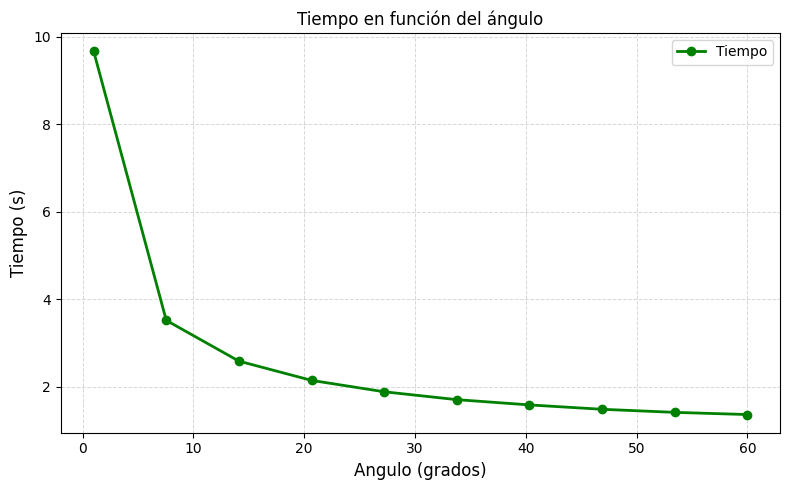

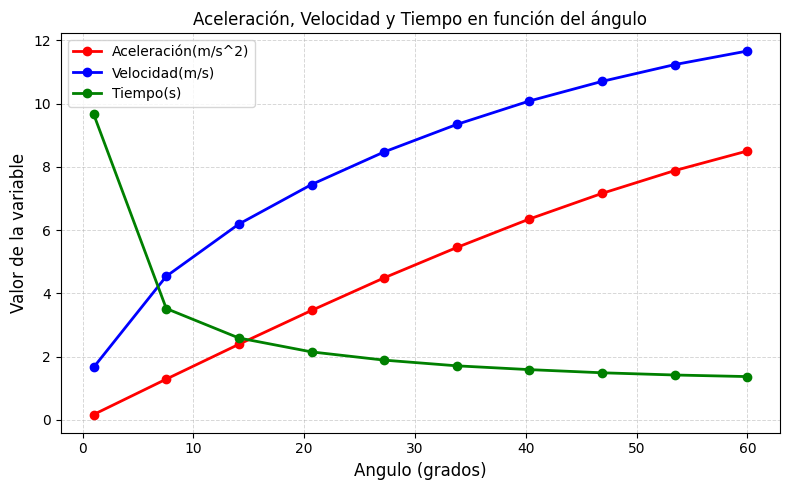

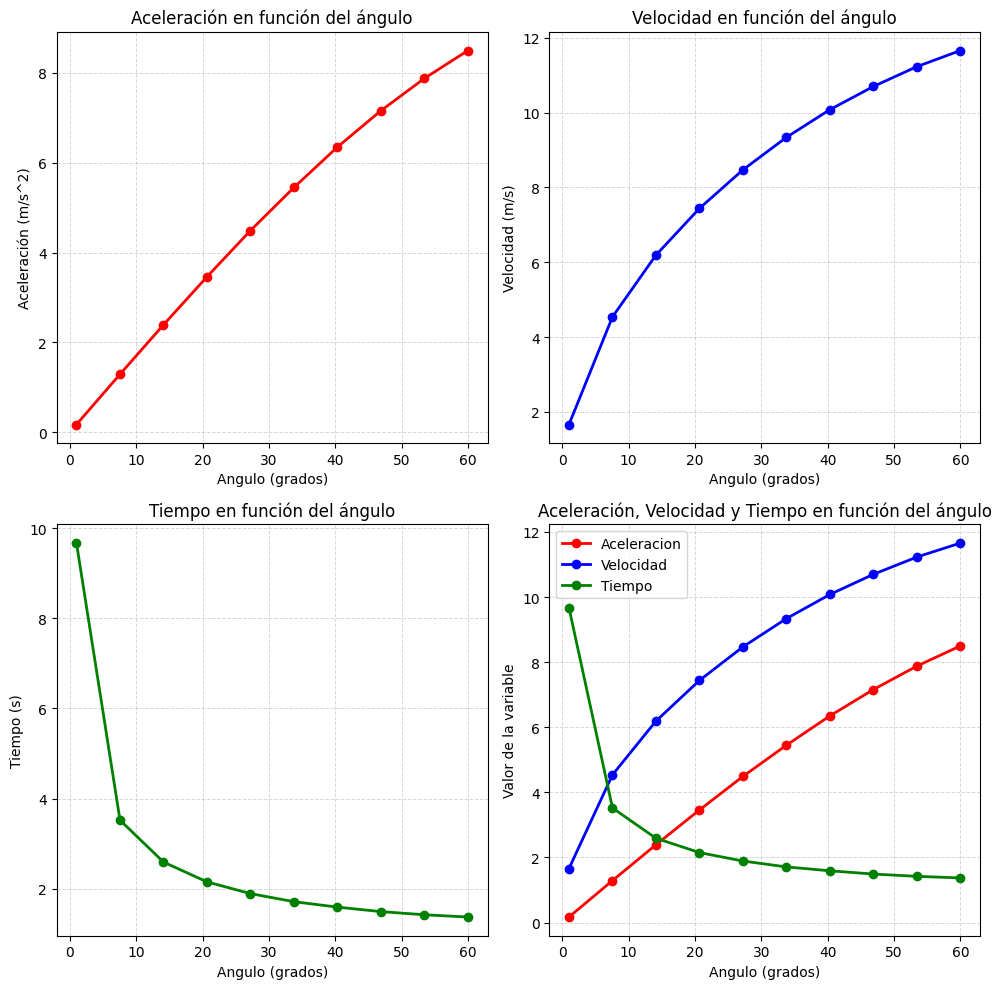

¿Desea ver por conservacion de energia?

1. Si
2. No
Ingrese su opción: 1

CASO SIN FRICCION CON CONSERVACION DE LA ENERGIA

----------
NOMBRE DEL ARCHIVO: DATOS: CONSERVACION DE LA ENERGIA SIN FRICCION
Número de datos: 10
----------
   1.0°   h =    0.140 m   U =    6.850 J   K =    6.850 J   v =    1.660 m/s a =    0.170 m/s^2 t =    9.670 s
   7.6°   h =    1.050 m   U =   51.600 J   K =   51.600 J   v =    4.540 m/s a =    1.290 m/s^2 t =    3.520 s
  14.1°   h =    1.950 m   U =   95.670 J   K =   95.670 J   v =    6.190 m/s a =    2.390 m/s^2 t =    2.590 s
  20.7°   h =    2.820 m   U =  138.490 J   K =  138.490 J   v =    7.440 m/s a =    3.460 m/s^2 t =    2.150 s
  27.2°   h =    3.660 m   U =  179.500 J   K =  179.500 J   v =    8.470 m/s a =    4.490 m/s^2 t =    1.890 s
  33.8°   h =    4.450 m   U =  218.160 J   K =  218.160 J   v =    9.340 m/s a =    5.450 m/s^2 t =    1.710 s
  40.3°   h =    5.180 m   U =  253.970 J   K =  253.970 J   v =   10.080 m/s a =    6.350 m/s

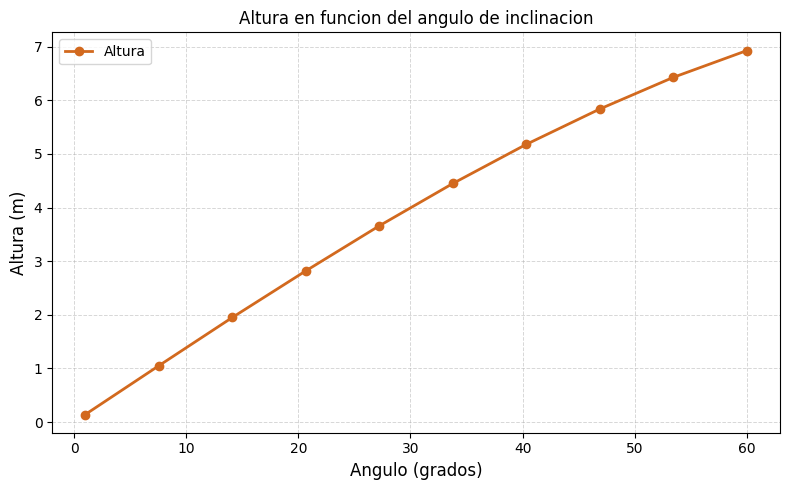

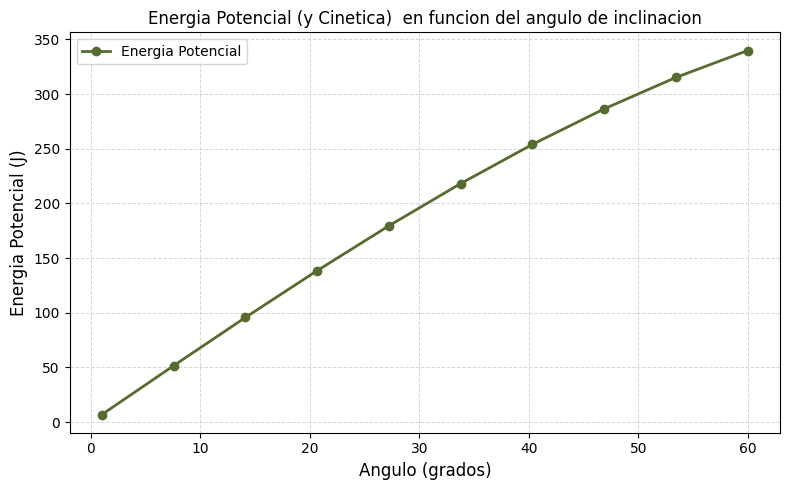

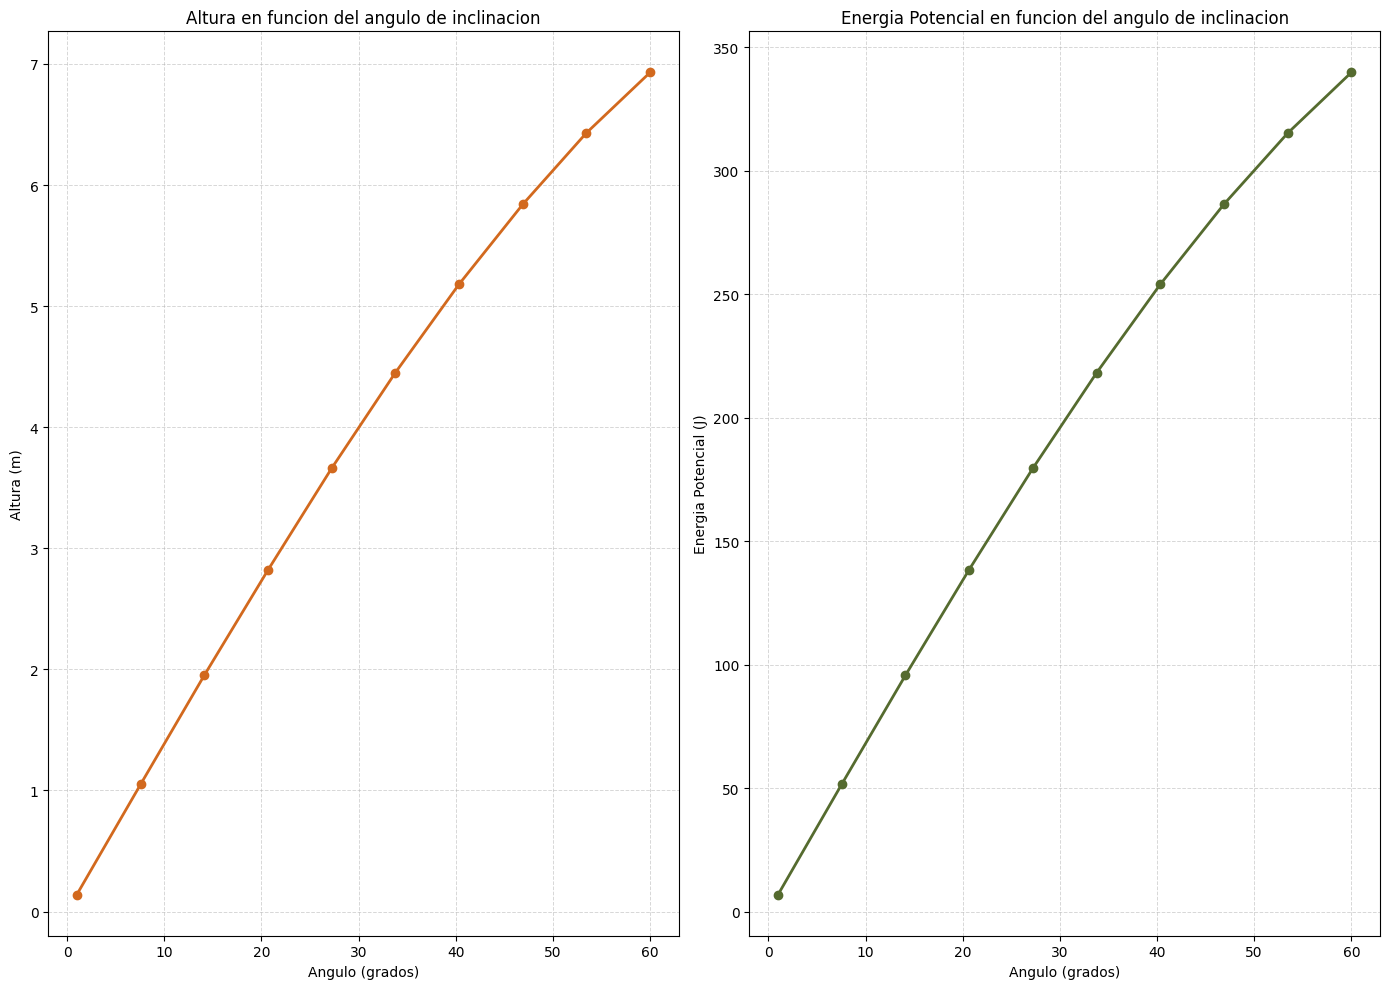

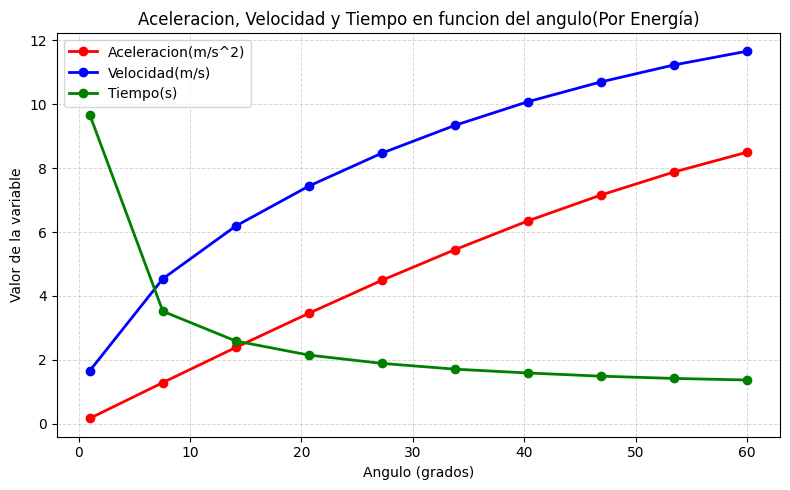

__________________________________________________


In [ ]:
#===============================================================================
#DATOS PEDIDOS AL USUARIO

masa = 5.0      #Masa del bloque en kg
d = 8           #Distancia del plano inclinado en m
mu = 0.2        #coeficiente de friccion
g = 9.81        #aceleracion de la gravedad en m/s^2

print("="*100)
print("-"*27 ,"PROGRAMA PLANO INCLINADO CON ANGULO VARIANTE","-"*27)
print("="*100)


print("\nIngrese el angulo maximo en grados (°): ")
#Usando un "while True" se impide que el usuario ingrese un numero mayor igual a 80 grados
while True:
    ang_flo= float(input())
    if ang_flo <= 85:
        break
    else:
        print("Por favor ingrese un angulo correcto menor que 80ª")

pat = int(input("Ingrese cada cuanto quiere que varie el angulo del plano inclinado: "))


ang = np.linspace(1, ang_flo, pat)
theta = np.radians(ang) #Angulo en radianes

print("_"*50)
print("\nMENU PRINCIPAL\n")
opt_menu = imprimir_menu(main_menu)
while opt_menu != len(main_menu):

    match opt_menu:

        case 1:
            print("\nCASO SIN FRICCION\n")
            Archivo_texto_nofr(ang,theta)
            archivo_DAT_AVSF = 'DATOS: ANGULO VARIANTE SIN FRICCION'
            graficas_equa_mov_sinfr(archivo_DAT_AVSF)


            print("="*100)
            print("¿Desea ver por conservacion de energia?\n")
            print("="*100)

            opt_second0 = imprimir_menu(second_menu)
            while opt_second0 != len(second_menu):

                match opt_second0:
                    case 1:
                        print("\nCASO SIN FRICCION CON CONSERVACION DE LA ENERGIA\n")
                        Archivotxt_cons_en_sinfr(ang, theta)
                        Archivo_DAT_AV_CONSENERGIA_SF = 'DATOS: CONSERVACION DE LA ENERGIA SIN FRICCION'
                        graficas_energia_sinfric(Archivo_DAT_AV_CONSENERGIA_SF)
                        break

                    case 2:
                        print("Continuar")
                        break
            break

        case 2:
            print("\nCASO CON FRICCION\n")
            Archivo_texto_confr(ang,theta,mu)
            archivo_DAT_AVCF = 'DATOS: ANGULO VARIANTE CON FRICCION'
            graficas_equa_mov_confric(archivo_DAT_AVCF,mu)


            print("-"*50)
            print("\nMU VARIANTE CON LA FUNCION GAUSSIANA\n")
            mu_gaussiana(ang,theta,mu)
            archivo_MU_GAUSSIANA = 'DATOS: MU VARIANTE CON ANGULO VARIANTE'
            mostrar_mu_gaussiana(archivo_MU_GAUSSIANA)
            print("-"*50)
            print(r'Grafica Distribucion Gaussiana de $\mu$')
            print("")
            mu_gaussiana_graf(mu)
            print("")

            print("="*100)
            print("¿Desea ver por conservacion de energia?\n")
            print("="*100)

            opt_second1 = imprimir_menu(second_menu)
            while opt_second1 != len(second_menu):
                match opt_second1:
                    case 1:
                        print("\nCASO CON FRICCION CON CONSERVACION DE LA ENERGIA\n")
                        Archivotxt_cons_en_confr(ang, theta,mu)
                        Archivo_DAT_AV_CONSENERGIA_CF = 'DATOS: CONSERVACION DE LA ENERGIA CON FRICCION'
                        graficas_energia_confric(Archivo_DAT_AV_CONSENERGIA_CF,mu)
                        break
                    case 2:
                        print("Continuar")
                        break
            break

        case 3:
            print("Salir")

        case _:
            print("Opcion incorrecta")
print("_"*50)

#===============================================================================


# CONFIRMACION GIT HUB